In [59]:
import numpy as np
import matplotlib.pyplot as plt

from helpers import load_csv_data
from implementations import (
    mean_squared_error_gd,
    mean_squared_error_sgd,
    least_squares,
    ridge_regression,
    logistic_regression,
    reg_logistic_regression,
)

SEED = 67
VALIDATION_FRACTION = 0.20

# Set this to None to use the whole training split for calibration.
# A subset makes the first calibration run much faster.
CALIBRATION_ROWS = 30000

# Threshold used when comparing hyperparameters.
# We calibrate a separate threshold for F1 after choosing each model's best settings.
DEFAULT_THRESHOLD = 0.0

DATA_PATH = "data/dataset/"

np.random.seed(SEED)

In [60]:
x_train_raw, x_test_raw, y_train, train_ids, test_ids = load_csv_data(
    DATA_PATH,
    sub_sample=False
)

y_train = np.asarray(y_train).ravel()

print("Train:", x_train_raw.shape)
print("Test:", x_test_raw.shape)
print("Labels:", np.unique(y_train, return_counts=True))

# Stratified split
rng = np.random.default_rng(SEED)

positive_idx = np.where(y_train == 1)[0]
negative_idx = np.where(y_train == -1)[0]

rng.shuffle(positive_idx)
rng.shuffle(negative_idx)

n_pos_val = int(len(positive_idx) * VALIDATION_FRACTION)
n_neg_val = int(len(negative_idx) * VALIDATION_FRACTION)

val_idx = np.concatenate([
    positive_idx[:n_pos_val],
    negative_idx[:n_neg_val]
])

train_idx = np.concatenate([
    positive_idx[n_pos_val:],
    negative_idx[n_neg_val:]
])

rng.shuffle(train_idx)
rng.shuffle(val_idx)

x_fit_raw = x_train_raw[train_idx]
y_fit = y_train[train_idx]

x_val_raw = x_train_raw[val_idx]
y_val = y_train[val_idx]

print("Fit split:", x_fit_raw.shape)
print("Validation split:", x_val_raw.shape)

Train: (328135, 321)
Test: (109379, 321)
Labels: (array([-1,  1]), array([299160,  28975]))
Fit split: (262508, 321)
Validation split: (65627, 321)


In [61]:
def fit_preprocessor(X):

    # Remove features that are entirely missing
    keep = np.any(np.isfinite(X), axis=0)
    X = X[:, keep].astype(float, copy=True)

    # Treat non-finite values as missing
    X[~np.isfinite(X)] = np.nan

    means = np.nanmean(X, axis=0)
    stds = np.nanstd(X, axis=0)

    # Avoid division by zero or NaN in case of constant features
    stds[~np.isfinite(stds) | (stds == 0)] = 1.0

    return keep, means, stds


def transform_features(X, keep, means, stds):
    X = X[:, keep].astype(float, copy=True)
    X[~np.isfinite(X)] = np.nan

    # Impute missing values using training means
    X = np.where(np.isnan(X), means, X)

    X = (X - means) / stds

    # Add bias term
    X = np.column_stack([np.ones(X.shape[0]), X])

    return X


keep_features, feature_means, feature_stds = fit_preprocessor(x_fit_raw)
X_fit = transform_features(
    x_fit_raw, keep_features, feature_means, feature_stds
)
X_val = transform_features(
    x_val_raw, keep_features, feature_means, feature_stds
)

# Optionally cap the number of rows used to tune parameters.
if CALIBRATION_ROWS is not None and len(y_fit) > CALIBRATION_ROWS:
    subset_rng = np.random.default_rng(SEED)
    selected = subset_rng.choice(len(y_fit), size=CALIBRATION_ROWS, replace=False)
    X_cal = X_fit[selected]
    y_cal = y_fit[selected]
else:
    X_cal = X_fit
    y_cal = y_fit

print("Features retained (before intercept):", int(keep_features.sum()))
print("Design matrix for calibration:", X_cal.shape)
print("Validation design matrix:", X_val.shape)
print("All values finite:", np.isfinite(X_cal).all() and np.isfinite(X_val).all())

Features retained (before intercept): 321
Design matrix for calibration: (30000, 322)
Validation design matrix: (65627, 322)
All values finite: True


In [62]:
def classification_metrics(y_true, scores, threshold=0.0):
    predictions = np.where(scores >= threshold, 1, -1)

    accuracy = float(np.mean(predictions == y_true))
    tp = int(np.sum((y_true == 1) & (predictions == 1)))
    fp = int(np.sum((y_true == -1) & (predictions == 1)))
    fn = int(np.sum((y_true == 1) & (predictions == -1)))

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )
    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "positive_predictions": int(np.sum(predictions == 1)),
    }


def best_f1_threshold(y_true, scores, n_candidates=201):
    # Quantiles focus candidate thresholds where the model's scores actually lie.
    thresholds = np.unique(np.quantile(scores, np.linspace(0, 1, n_candidates)))
    best_threshold = 0.0
    best_metrics = classification_metrics(y_true, scores, best_threshold)

    for threshold in thresholds:
        metrics = classification_metrics(y_true, scores, float(threshold))
        if metrics["f1"] > best_metrics["f1"]:
            best_threshold = float(threshold)
            best_metrics = metrics

    return best_threshold, best_metrics

In [63]:
calibration_results = {}


def evaluate_candidate(model_name, params, fit_function):

    weights, train_loss = fit_function()
    if not np.isfinite(weights).all() or not np.isfinite(train_loss):
        raise FloatingPointError("non-finite weights or loss")

    val_scores = X_val @ weights
    if not np.isfinite(val_scores).all():
        raise FloatingPointError("non-finite validation scores")

    metrics = classification_metrics(
        y_val, val_scores, threshold=DEFAULT_THRESHOLD
    )
    record = {
        "model": model_name,
        "params": dict(params),
        "train_loss": float(train_loss),
        "validation_accuracy": metrics["accuracy"],
        "validation_f1": metrics["f1"],
        "validation_precision": metrics["precision"],
        "validation_recall": metrics["recall"],
        "positive_predictions": metrics["positive_predictions"],
    }

    calibration_results.setdefault(model_name, []).append(record)
    print(
        f"{model_name:24s} params={params} "
        f"loss={record['train_loss']:.5f} "
        f"acc={record['validation_accuracy']:.4f} "
        f"F1={record['validation_f1']:.4f} "
    )
    return record

In [64]:
calibration_results["MSE gradient descent"] = []

for max_iters in [100, 300, 500, 1000, 2000]:
    for gamma in [0.001, 0.003, 0.01, 0.03]:
        evaluate_candidate(
            "MSE gradient descent",
            {"max_iters": max_iters, "gamma": gamma},
            lambda max_iters=max_iters, gamma=gamma: mean_squared_error_gd(
                y_cal, X_cal, np.zeros(X_cal.shape[1]), max_iters, gamma
            ),
        )

MSE gradient descent     params={'max_iters': 100, 'gamma': 0.001} loss=0.42450 acc=0.7910 F1=0.3616 
MSE gradient descent     params={'max_iters': 100, 'gamma': 0.003} loss=0.32782 acc=0.8733 F1=0.3835 
MSE gradient descent     params={'max_iters': 100, 'gamma': 0.01} loss=0.18549 acc=0.9131 F1=0.1132 
MSE gradient descent     params={'max_iters': 100, 'gamma': 0.03} loss=0.13990 acc=0.9117 F1=0.0133 
MSE gradient descent     params={'max_iters': 300, 'gamma': 0.001} loss=0.32795 acc=0.8735 F1=0.3834 
MSE gradient descent     params={'max_iters': 300, 'gamma': 0.003} loss=0.19605 acc=0.9131 F1=0.1420 
MSE gradient descent     params={'max_iters': 300, 'gamma': 0.01} loss=0.13995 acc=0.9117 F1=0.0133 
MSE gradient descent     params={'max_iters': 300, 'gamma': 0.03} loss=0.13844 acc=0.9119 F1=0.0113 
MSE gradient descent     params={'max_iters': 500, 'gamma': 0.001} loss=0.26553 acc=0.9027 F1=0.3147 
MSE gradient descent     params={'max_iters': 500, 'gamma': 0.003} loss=0.15653 acc=0.

In [65]:
calibration_results["MSE stochastic gradient descent"] = []

for gamma in [1e-6, 3e-6, 1e-5, 3e-5, 1e-4]:
    def fit_sgd(max_iters=100000, gamma=gamma):
        np.random.seed(SEED)
        return mean_squared_error_sgd(
            y_cal, X_cal, np.zeros(X_cal.shape[1]), max_iters, gamma
        )

    evaluate_candidate(
        "MSE stochastic gradient descent",
        {"max_iters": 100000, "gamma": gamma},
        fit_sgd,
    )

MSE stochastic gradient descent params={'max_iters': 100000, 'gamma': 1e-06} loss=0.42468 acc=0.7887 F1=0.3609 
MSE stochastic gradient descent params={'max_iters': 100000, 'gamma': 3e-06} loss=0.32834 acc=0.8713 F1=0.3829 
MSE stochastic gradient descent params={'max_iters': 100000, 'gamma': 1e-05} loss=0.18645 acc=0.9130 F1=0.1117 
MSE stochastic gradient descent params={'max_iters': 100000, 'gamma': 3e-05} loss=0.14378 acc=0.9117 F1=0.0279 
MSE stochastic gradient descent params={'max_iters': 100000, 'gamma': 0.0001} loss=0.14187 acc=0.9115 F1=0.0143 


In [66]:
calibration_results["Least squares"] = []

evaluate_candidate(
    "Least squares",
    {},
    lambda: least_squares(y_cal, X_cal),
)

Least squares            params={} loss=0.13678 acc=0.9124 F1=0.0284 


{'model': 'Least squares',
 'params': {},
 'train_loss': 0.13678121264050985,
 'validation_accuracy': 0.912383622594359,
 'validation_f1': 0.028387968908415002,
 'validation_precision': 0.6829268292682927,
 'validation_recall': 0.01449525452976704,
 'positive_predictions': 123}

In [67]:
calibration_results["Ridge regression"] = []

for lambda_ in [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]:
    evaluate_candidate(
        "Ridge regression",
        {"lambda_": lambda_},
        lambda lambda_=lambda_: ridge_regression(y_cal, X_cal, lambda_),
    )

Ridge regression         params={'lambda_': 1e-05} loss=0.13683 acc=0.9124 F1=0.0264 
Ridge regression         params={'lambda_': 0.0001} loss=0.13718 acc=0.9121 F1=0.0207 
Ridge regression         params={'lambda_': 0.001} loss=0.13750 acc=0.9121 F1=0.0187 
Ridge regression         params={'lambda_': 0.01} loss=0.13802 acc=0.9119 F1=0.0140 
Ridge regression         params={'lambda_': 0.1} loss=0.14846 acc=0.9120 F1=0.0253 
Ridge regression         params={'lambda_': 1.0} loss=0.29277 acc=0.9056 F1=0.2978 


In [68]:
calibration_results["Logistic regression"] = []

for gamma in [0.003, 0.01, 0.03, 0.1]:
    evaluate_candidate(
        "Logistic regression",
        {"max_iters": 10000, "gamma": gamma},
        lambda max_iters=10000, gamma=gamma: logistic_regression(
            y_cal, X_cal, np.zeros(X_cal.shape[1]), max_iters, gamma
        ),
    )

Logistic regression      params={'max_iters': 10000, 'gamma': 0.003} loss=0.23499 acc=0.9138 F1=0.1458 
Logistic regression      params={'max_iters': 10000, 'gamma': 0.01} loss=0.22581 acc=0.9135 F1=0.1898 
Logistic regression      params={'max_iters': 10000, 'gamma': 0.03} loss=0.22400 acc=0.9135 F1=0.2070 
Logistic regression      params={'max_iters': 10000, 'gamma': 0.1} loss=0.22328 acc=0.9132 F1=0.2146 


In [69]:
calibration_results["Regularized logistic regression"] = []

for lambda_ in [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]:
    for gamma in [0.003, 0.01, 0.03, 0.1]:
        evaluate_candidate(
            "Regularized logistic regression",
            {"lambda_": lambda_, "gamma": gamma, "max_iters": 2000},
            lambda lambda_=lambda_, gamma=gamma, max_iters=2000: reg_logistic_regression(
                y_cal,
                X_cal,
                lambda_,
                np.zeros(X_cal.shape[1]),
                max_iters,
                gamma,
            ),
        )

Regularized logistic regression params={'lambda_': 1e-05, 'gamma': 0.003, 'max_iters': 2000} loss=0.31534 acc=0.9133 F1=0.1334 
Regularized logistic regression params={'lambda_': 1e-05, 'gamma': 0.01, 'max_iters': 2000} loss=0.24364 acc=0.9137 F1=0.1286 
Regularized logistic regression params={'lambda_': 1e-05, 'gamma': 0.03, 'max_iters': 2000} loss=0.22798 acc=0.9135 F1=0.1755 
Regularized logistic regression params={'lambda_': 1e-05, 'gamma': 0.1, 'max_iters': 2000} loss=0.22445 acc=0.9135 F1=0.2007 
Regularized logistic regression params={'lambda_': 0.0001, 'gamma': 0.003, 'max_iters': 2000} loss=0.31543 acc=0.9133 F1=0.1334 
Regularized logistic regression params={'lambda_': 0.0001, 'gamma': 0.01, 'max_iters': 2000} loss=0.24376 acc=0.9137 F1=0.1286 
Regularized logistic regression params={'lambda_': 0.0001, 'gamma': 0.03, 'max_iters': 2000} loss=0.22809 acc=0.9135 F1=0.1743 
Regularized logistic regression params={'lambda_': 0.0001, 'gamma': 0.1, 'max_iters': 2000} loss=0.22452 ac

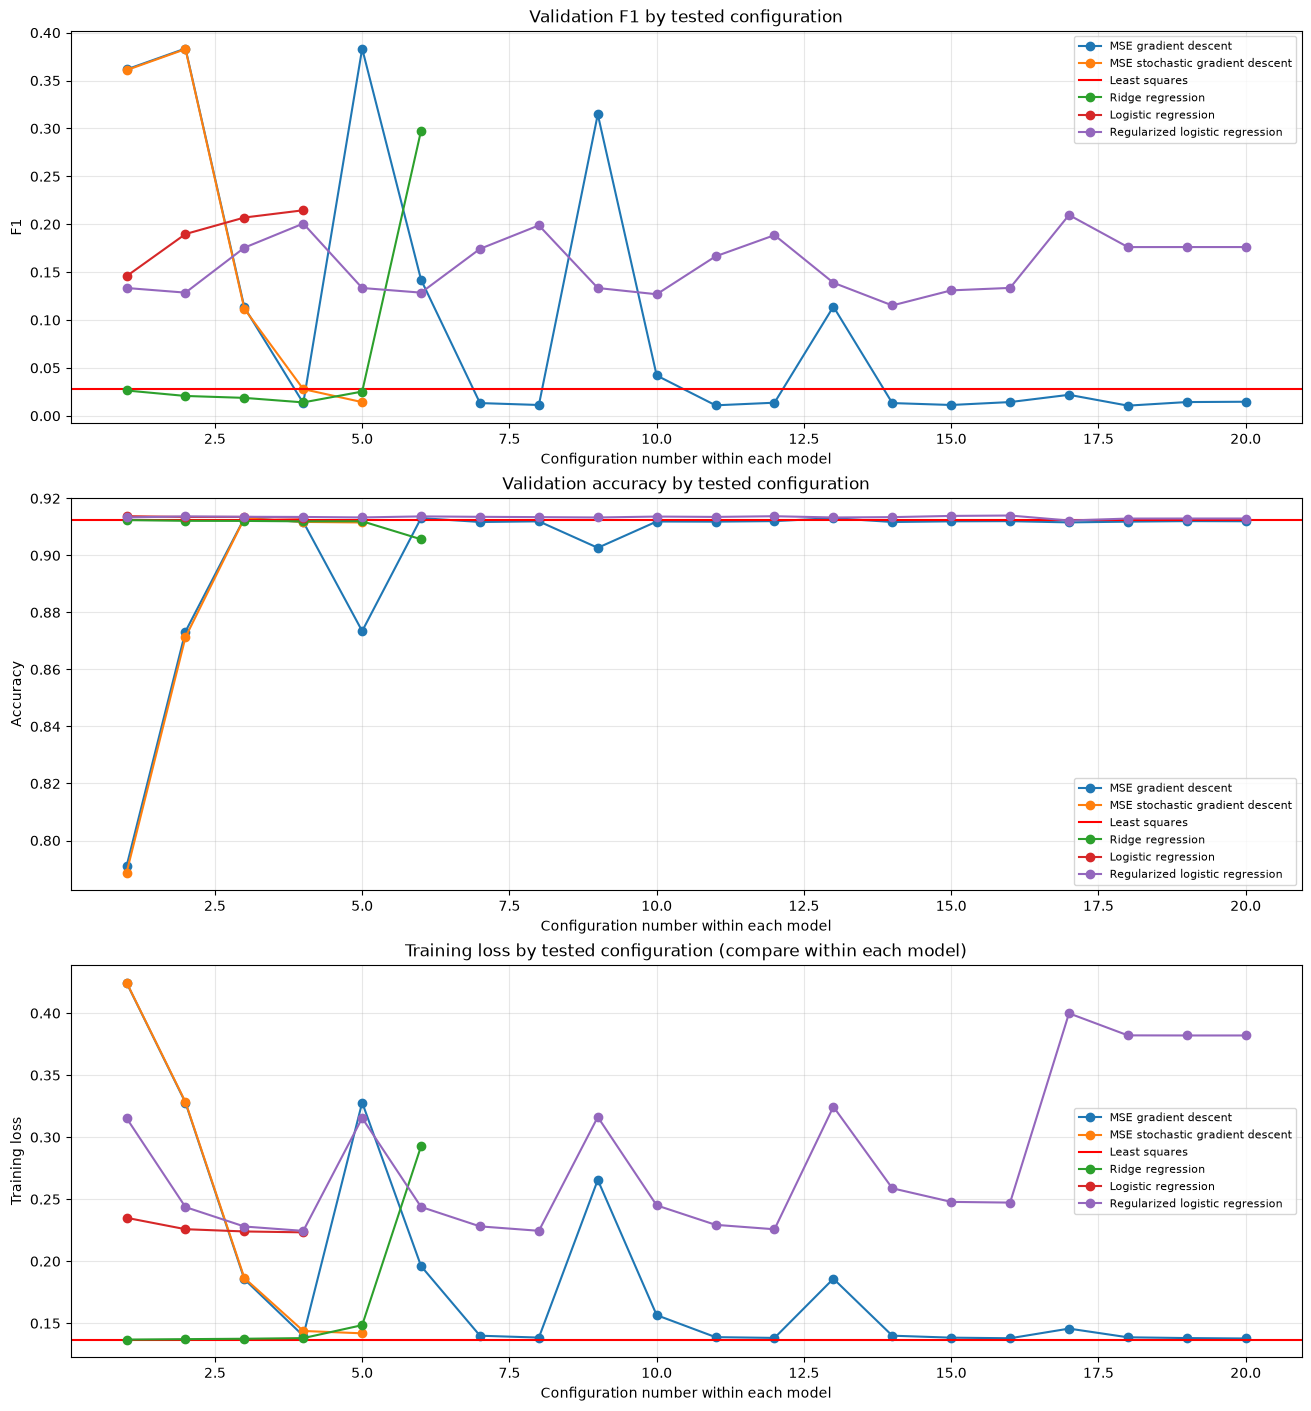

In [70]:
def valid_records(records, metric):
    return [
        r for r in records
        if np.isfinite(r[metric])
    ]


fig, axes = plt.subplots(3, 1, figsize=(13, 14), constrained_layout=True)
model_names = list(calibration_results.keys())

for model_name in model_names:
    records = valid_records(calibration_results[model_name], "validation_f1")
    if not records:
        continue

    x = np.arange(1, len(records) + 1)

    if model_name == "Least squares":
        axes[0].axhline(
            y=records[0]["validation_f1"],
            linestyle="-",
            color="red",
            label=model_name
        )
        axes[1].axhline(
            y=records[0]["validation_accuracy"],
            linestyle="-",
            color="red",
            label=model_name
        )
        axes[2].axhline(
            y=records[0]["train_loss"],
            linestyle="-",
            color="red",
            label=model_name
        )
    else:
        axes[0].plot(x, [r["validation_f1"] for r in records],
                     marker="o", label=model_name)
        axes[1].plot(x, [r["validation_accuracy"] for r in records],
                     marker="o", label=model_name)
        axes[2].plot(x, [r["train_loss"] for r in records],
                     marker="o", label=model_name)


axes[0].set_title("Validation F1 by tested configuration")
axes[0].set_ylabel("F1")
axes[1].set_title("Validation accuracy by tested configuration")
axes[1].set_ylabel("Accuracy")
axes[2].set_title("Training loss by tested configuration (compare within each model)")
axes[2].set_ylabel("Training loss")
axes[2].set_xlabel("Configuration number within each model")

for ax in axes:
    ax.set_xlabel("Configuration number within each model")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best", fontsize=8)

plt.show()

In [ ]:
best_records = []

for model_name, records in calibration_results.items():
    eligible = [
        r for r in records
        if np.isfinite(r["train_loss"])
    ]
    if not eligible:
        print(f"No successful configurations for {model_name}")
        continue

    best = max(eligible, key=lambda r: r["train_loss"])
    best_records.append(best)

print("Selection metric: train_loss")
print()

for record in sorted(
    best_records,
    key=lambda r: r["train_loss"],
    reverse=True,
):
    print(
        f"{record['model']}: params={record['params']} | "
        f"val_accuracy={record['validation_accuracy']:.4f} | "
        f"val_F1={record['validation_f1']:.4f} | "
        f"train_loss={record['train_loss']:.5f}"
    )

Selection metric: f1

MSE stochastic gradient descent: params={'max_iters': 100000, 'gamma': 1e-06} | val_accuracy=0.7887 | val_F1=0.3609 | train_loss=0.42468
MSE gradient descent: params={'max_iters': 100, 'gamma': 0.001} | val_accuracy=0.7910 | val_F1=0.3616 | train_loss=0.42450
Regularized logistic regression: params={'lambda_': 0.1, 'gamma': 0.003, 'max_iters': 2000} | val_accuracy=0.9122 | val_F1=0.2097 | train_loss=0.39985
Ridge regression: params={'lambda_': 1.0} | val_accuracy=0.9056 | val_F1=0.2978 | train_loss=0.29277
Logistic regression: params={'max_iters': 10000, 'gamma': 0.003} | val_accuracy=0.9138 | val_F1=0.1458 | train_loss=0.23499
Least squares: params={} | val_accuracy=0.9124 | val_F1=0.0284 | train_loss=0.13678


In [72]:
def fit_model_from_record(record, X, y):
    name = record["model"]
    params = record["params"]
    initial_w = np.zeros(X.shape[1])

    if name == "MSE gradient descent":
        return mean_squared_error_gd(
            y, X, initial_w, params["max_iters"], params["gamma"]
        )
    if name == "MSE stochastic gradient descent":
        np.random.seed(SEED)
        return mean_squared_error_sgd(
            y, X, initial_w, params["max_iters"], params["gamma"]
        )
    if name == "Least squares":
        return least_squares(y, X)
    if name == "Ridge regression":
        return ridge_regression(y, X, params["lambda_"])
    if name == "Logistic regression":
        return logistic_regression(
            y, X, initial_w, params["max_iters"], params["gamma"]
        )
    if name == "Regularized logistic regression":
        return reg_logistic_regression(
            y, X, params["lambda_"], initial_w,
            params["max_iters"], params["gamma"]
        )


final_calibration_summary = []

for record in best_records:
    weights, train_loss = fit_model_from_record(record, X_fit, y_fit)
    scores = X_val @ weights
    threshold, metrics = best_f1_threshold(y_val, scores)

    final_calibration_summary.append({
        "model": record["model"],
        "params": record["params"],
        "train_loss": float(train_loss),
        "f1_threshold": threshold,
        "threshold_tuned_f1": metrics["f1"],
        "threshold_tuned_accuracy": metrics["accuracy"],
        "precision": metrics["precision"],
        "recall": metrics["recall"],
    })

for row in sorted(final_calibration_summary, key=lambda r: r["threshold_tuned_f1"], reverse=True):
    print(
        f"{row['model']}: params={row['params']} | "
        f"threshold={row['f1_threshold']:.5f} | "
        f"F1={row['threshold_tuned_f1']:.4f} | "
        f"accuracy={row['threshold_tuned_accuracy']:.4f} | "
        f"loss={row['train_loss']:.5f}"
    )

Least squares: params={} | threshold=-0.54593 | F1=0.4182 | accuracy=0.8759 | loss=0.13668
Logistic regression: params={'max_iters': 10000, 'gamma': 0.003} | threshold=-1.35321 | F1=0.4116 | accuracy=0.8568 | loss=0.23528
Regularized logistic regression: params={'lambda_': 0.1, 'gamma': 0.003, 'max_iters': 2000} | threshold=-0.43022 | F1=0.4021 | accuracy=0.8575 | loss=0.39907
Ridge regression: params={'lambda_': 1.0} | threshold=-0.11089 | F1=0.3970 | accuracy=0.8533 | loss=0.29221
MSE gradient descent: params={'max_iters': 100, 'gamma': 0.001} | threshold=0.02346 | F1=0.3801 | accuracy=0.8430 | loss=0.42464
MSE stochastic gradient descent: params={'max_iters': 100000, 'gamma': 1e-06} | threshold=0.02562 | F1=0.3769 | accuracy=0.8453 | loss=0.42486


In [73]:
# Print a plain-text table without requiring pandas.
headers = ["Model", "Best parameters", "F1 threshold", "Val F1", "Val accuracy"]
rows = []

for row in sorted(final_calibration_summary, key=lambda r: r["threshold_tuned_f1"], reverse=True):
    rows.append([
        row["model"],
        str(row["params"]),
        f"{row['f1_threshold']:.5f}",
        f"{row['threshold_tuned_f1']:.4f}",
        f"{row['threshold_tuned_accuracy']:.4f}",
    ])

widths = [
    max(len(headers[i]), *(len(r[i]) for r in rows)) if rows else len(headers[i])
    for i in range(len(headers))
]

print(" | ".join(headers[i].ljust(widths[i]) for i in range(len(headers))))
print("-+-".join("-" * widths[i] for i in range(len(headers))))
for row in rows:
    print(" | ".join(row[i].ljust(widths[i]) for i in range(len(headers))))

Model                           | Best parameters                                     | F1 threshold | Val F1 | Val accuracy
--------------------------------+-----------------------------------------------------+--------------+--------+-------------
Least squares                   | {}                                                  | -0.54593     | 0.4182 | 0.8759      
Logistic regression             | {'max_iters': 10000, 'gamma': 0.003}                | -1.35321     | 0.4116 | 0.8568      
Regularized logistic regression | {'lambda_': 0.1, 'gamma': 0.003, 'max_iters': 2000} | -0.43022     | 0.4021 | 0.8575      
Ridge regression                | {'lambda_': 1.0}                                    | -0.11089     | 0.3970 | 0.8533      
MSE gradient descent            | {'max_iters': 100, 'gamma': 0.001}                  | 0.02346      | 0.3801 | 0.8430      
MSE stochastic gradient descent | {'max_iters': 100000, 'gamma': 1e-06}               | 0.02562      | 0.3769 | 0.8453      
